# 06 · Who should the call centre call?

Notebook 05 found no detectable average effect of the retention call. An average near zero can
still hide customers the call helps and customers it annoys into leaving, so the plan asks
whether any ranking finds the ones worth calling:

- **churn risk:** a churn model fitted on held-back customers only (risk without a call), the
  usual way retention lists are built;
- **T-learner** and **X-learner:** LightGBM models of the call's effect on churn.

Every customer is scored by models that never saw them (5-fold cross-fitting). Because who was
called depended on the profile (notebook 05), each ranking is judged with inverse-propensity
weights. **Decision rule (from the plan):** uplift targeting is recommended only if its Qini
beats churn-risk ranking with a paired bootstrap interval that excludes zero.

| | |
|---|---|
| **Question** | Even with no average effect, could ranking customers (by churn risk or by predicted uplift) find the ones the call helps? |
| **Answer** | No. Neither churn risk nor two uplift models (T- and X-learner) beats calling at random. The plan's recommendation: if the call centre calls at all, call at random within the eligible group, and treat the next campaign as an experiment. |
| **Next** | [Notebook 07](07_retention_decision.ipynb) turns all of this into a decision. |

In [1]:
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "telecom.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import warnings

warnings.filterwarnings("ignore", message=".*penalty.*")   # scikit-learn 1.8+ renames the L1 setting

import matplotlib.pyplot as plt
import numpy as np

from src import records
from src.data import telecom
from src.experiment import campaign

df, SOURCE = telecom.load()
t, y = df[telecom.TREAT].to_numpy(), df[telecom.OUTCOME].to_numpy()
X = campaign.design(df, telecom.PCS, telecom.FACTORS)
e = np.load(telecom.cache_dir(SOURCE) / "propensity.npy")
keep = (e >= 0.05) & (e <= 0.95)
X, t, y, e = X[keep], t[keep], y[keep], e[keep]
w = campaign.ipw_weights(t, e)
print(f"source: {SOURCE}; {len(t):,} customers inside the overlap region; {int((y[t == 0]).sum())} churners "
      f"among {int((1 - t).sum()):,} held back")

source: real; 11,620 customers inside the overlap region; 105 churners among 2,865 held back


## 1. Scores, cross-fitted

In [2]:
scores = campaign.cross_fit_scores(X, t, y, propensity=float(t.mean()))
scores["random"] = np.random.default_rng(0).random(len(t))
print({k: round(float(np.corrcoef(v, scores["churn_risk"])[0, 1]), 2) for k, v in scores.items()})

{'churn_risk': 1.0, 't_learner': 0.2, 'x_learner': 0.5, 'random': -0.01}


## 2. Do the rankings beat random, and does uplift beat risk?

Qini coefficient: the area between a ranking's cumulative churn-prevented curve and the line
random calling would give, per customer (positive = better than random). Top 20% / 40%: churn
prevented per customer among the customers each ranking would call first. Intervals from
1,000 bootstrap resamples of customers, the same resamples for every ranking.

In [3]:
boot = campaign.bootstrap_targeting(scores, t, y, w=w, boot=1000)
point = boot[boot["draw"] == 0].set_index("ranking")
draws = boot[boot["draw"] > 0]
ci = draws.groupby("ranking").agg(**{f"{m}_{q}": (m, lambda s, q=q: np.percentile(s, q))
                                    for m in ("qini", "top_20", "top_40") for q in (2.5, 97.5)})
summary = point[["qini", "top_20", "top_40"]].join(ci)
wide = draws.pivot(index="draw", columns="ranking", values="qini")
paired = {name: {"diff": float(point.loc[name, "qini"] - point.loc["churn_risk", "qini"]),
                 "ci": [float(np.percentile(wide[name] - wide["churn_risk"], q)) for q in (2.5, 97.5)]}
          for name in ("t_learner", "x_learner")}
print("uplift Qini minus churn-risk Qini:", {k: (round(v["diff"], 5), [round(x, 5) for x in v["ci"]])
                                             for k, v in paired.items()})
summary.round(5)

uplift Qini minus churn-risk Qini: {'t_learner': (-0.00051, [-0.00333, 0.00199]), 'x_learner': (-0.00088, [-0.00232, 0.00038])}


,qini,top_20,top_40,qini_2.5,qini_97.5,top_20_2.5,top_20_97.5,top_40_2.5,top_40_97.5
ranking,,,,,,,,,
churn_risk,-0.00012,0.00373,0.00423,-0.00162,0.00159,-0.02944,0.04397,-0.01576,0.02571
t_learner,-0.00063,0.00177,-0.00011,-0.00243,0.00102,-0.01887,0.02400,-0.01141,0.01166
x_learner,-0.00100,-0.00928,-0.00166,-0.00244,0.00051,-0.03404,0.02004,-0.01768,0.01587
random,0.00039,0.01767,0.00418,-0.00106,0.00184,-0.00556,0.04976,-0.01090,0.02218


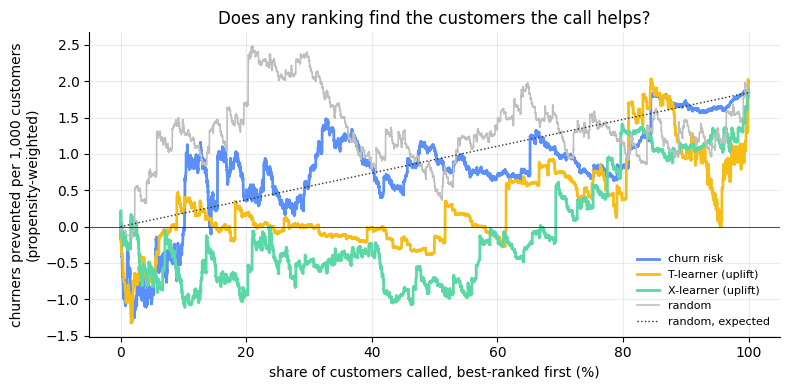

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
colours = {"churn_risk": "#5B8FF9", "t_learner": "#F6BD16", "x_learner": "#5AD8A6", "random": "#BFBFBF"}
labels = {"churn_risk": "churn risk", "t_learner": "T-learner (uplift)", "x_learner": "X-learner (uplift)",
          "random": "random"}
for name, s in scores.items():
    frac, q = campaign.qini_curve(s, t, y, w)
    ax.plot(frac * 100, q / w.sum() * 1000, color=colours[name], lw=2 if name != "random" else 1.2, label=labels[name])
frac, q = campaign.qini_curve(scores["random"], t, y, w)
ax.plot([0, 100], [0, q[-1] / w.sum() * 1000], ls=":", color="#2B2B2B", lw=1, label="random, expected")
ax.axhline(0, color="#2B2B2B", lw=0.6)
ax.set(xlabel="share of customers called, best-ranked first (%)",
       ylabel="churners prevented per 1,000 customers\n(propensity-weighted)",
       title="Does any ranking find the customers the call helps?")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "06_campaign_targeting.png", SOURCE)

**How to read the figure (a Qini curve).** Move right as you call more customers, best-ranked first; the height is how many churners the calls prevented per 1,000 customers. A good ranking rises steeply at the left, above the dotted line for random calling. Here every curve hugs the random line or falls below it.

**Tracked in MLflow.** Each ranking (churn risk, T-learner, X-learner) is logged as a run with the
model settings and its Qini and top-share results, in the same experiment as notebook 05.

In [5]:
from src.models.tracking import log_run

for name in ("churn_risk", "t_learner", "x_learner"):
    s = summary.loc[name]
    log_run(f"telecom_campaign_{SOURCE}", f"ranking_{name}",
            params={"ranking": name, "model": "lightgbm", "folds": 5, **campaign.LGBM_PARAMS},
            metrics={"qini": s["qini"], "qini_ci_low": s["qini_2.5"], "qini_ci_high": s["qini_97.5"],
                     "top_20": s["top_20"], "top_40": s["top_40"]},
            tags={"data": SOURCE, "stage": "targeting"})

In [6]:
beats_risk = {k: v["ci"][0] > 0 for k, v in paired.items()}
better_than_random = {k: bool(summary.loc[k, "qini_2.5"] > 0) for k in ("churn_risk", "t_learner", "x_learner")}
if any(beats_risk.values()):
    rec = "uplift targeting"
elif better_than_random["churn_risk"]:
    rec = "call by churn risk"
else:
    rec = "no ranking beats random: call at random within the eligible group"
record = {"customers": int(len(t)), "summary": summary.reset_index().to_dict(orient="records"),
          "uplift_vs_risk": paired, "beats_risk": beats_risk, "better_than_random": better_than_random,
          "recommendation": rec}
print("wrote", records.write("06_campaign_targeting", record, SOURCE).name)
lines = [f"{labels[k]}: Qini {summary.loc[k, 'qini']:+.5f} [{summary.loc[k, 'qini_2.5']:+.5f}, "
         f"{summary.loc[k, 'qini_97.5']:+.5f}]" for k in ("churn_risk", "t_learner", "x_learner")]
lines.append(f"Recommendation under the plan's rule: {rec}.")
print("\n".join(f"{i}. {s}" for i, s in enumerate(lines, 1)))

wrote 06_campaign_targeting.json
1. churn risk: Qini -0.00012 [-0.00162, +0.00159]
2. T-learner (uplift): Qini -0.00063 [-0.00243, +0.00102]
3. X-learner (uplift): Qini -0.00100 [-0.00244, +0.00051]
4. Recommendation under the plan's rule: no ranking beats random: call at random within the eligible group.


## Takeaways

- **Uplift models are not magic:** with a small, noisy effect they cannot find who responds, and here they do no better than random.
- **Ranking by churn risk is not the same as ranking by who the call helps**, and neither works here.

**Next:** [notebook 07](07_retention_decision.ipynb), the decision.